In [2]:
import argparse
import os
import sys
sys.path.insert(0, "src")
from ultralytics import YOLO
from medseg.models.yolo.evaluate import evaluate_yolo

In [ ]:
def main():
    ap = argparse.ArgumentParser()
    data = "data/yolo/kvasir/yolo/data.yaml" #path to yaml
    coco_root = "data/yolo/kvasir/coco ap.add_argument"#coco root for eval
    ap.add_argument("--model", default="yolo11s-seg.pt") #default model (pre-trained)
    epochs = 40 #ap.add_argument("--epochs", type=int, default=40)
    ap.add_argument("--imgsz", type=int, default=512)
    ap.add_argument("--batch", type=int, default=-1) #-1 arg is auto-batch
    ap.add_argument("--device", default=None, help="e.g. 0 | cpu | mps")
    ap.add_argument("--workers", type=int, default=8)
    ap.add_argument("--conf", type=float, default=0.25, help="inference confidence for eval")
    ap.add_argument("--tol", type=float, default=2.0) #nsd tolerance in pixels
    ap.add_argument("--name", default="yolo_seg")
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--split", default="test")
    #additional training args
    ap.add_argument("--mosaic", type=float, default=0.5)
    ap.add_argument("--close-mosaic", type=int, default=5) #closes auto-mosaic at a specified point
    ap.add_argument("--optimizer", default="auto")
    #ap.add_argument("--lr0", type=float, default=None) #initial LR
    #ap.add_argument("--lrf", type=float, default=None) #final LR
    #ap.add_argument("--weight-decay", type=float, default=None) #these values are generally finally set by the auto optimizer
    args = ap.parse_args()
    model = YOLO(args.model)
    model.train(
        data=args.data,
        epochs=args.epochs,
        imgsz=args.imgsz,
        batch=args.batch,
        device=args.device,
        workers=args.workers,
        seed=args.seed,          # keep the comparison controlled
        name=args.name,
        mosaic = args.mosaic,
        close_mosaic=args.close_mosaic,
        optimizer=args.optimizer,
        plots=True,
    )
    # Ask the trainer where it actually saved, rather than assuming ./runs/segment
    save_dir = getattr(model.trainer, "save_dir", None)
    best = (os.path.join(str(save_dir), "weights", "best.pt") if save_dir
            else os.path.join("runs", "segment", args.name, "weights", "best.pt"))
    if not os.path.isfile(best):
        raise FileNotFoundError(f"trained checkpoint not found: {best}")
    print(f"\nbest checkpoint: {best}")
    evaluate_yolo(
        weights=best,
        coco_root= data/yolo/kvasir/coco,
        split=args.split,
        imgsz=args.imgsz,
        conf=args.conf,
        tol=args.tol,
        device=args.device,
        out_json=os.path.join("results", "metrics", f"{args.name}_{args.split}.json"),
    )
 --data data/yolo/kvasir/yolo/data.yaml --coco-root data/yolo/kvasir/coco --epochs 40 --imgsz 512 --mosaic 0.5 --close-mosaic 5 --name yolo_kvasir_e40 --batch 32


In [2]:
os.makedirs("results/metrics", exist_ok=True)

from medseg.models.yolo.evaluate import evaluate_yolo

result = evaluate_yolo(
    weights="runs/segment/yolo_kvasir_e40/weights/best.pt",   # from Cell 2
    coco_root="data/yolo/kvasir/coco",
    split="test",
    imgsz=512,
    conf=0.25,
    tol=2.0,
    device=0,          # or "cpu" if no GPU on this kernel
    out_json="results/metrics/yolo_kvasir_e40_test.json",
)
result

wrote results/metrics/yolo_kvasir_e40_test.json
YOLO-seg test: dice=0.8969  nsd=0.6052  (n=200, both_empty=0)


{'arm': 'yolo_seg',
 'weights': 'runs/segment/yolo_kvasir_e40/weights/best.pt',
 'split': 'test',
 'imgsz': 512,
 'conf': 0.25,
 'tol': 2.0,
 'n_images': 200,
 'n_both_empty': 0,
 'dice': 0.8968574098530147,
 'nsd': 0.6052482788485132,
 'dice_excl_empty': 0.8968574098530147,
 'per_image': [{'image_id': 0,
   'file_name': 'kvasir_test_00000.png',
   'dice': 0.9772138595581055,
   'nsd': 0.6745997667312622,
   'gt_empty': False,
   'pred_empty': False},
  {'image_id': 1,
   'file_name': 'kvasir_test_00001.png',
   'dice': 0.9520452618598938,
   'nsd': 0.5271983742713928,
   'gt_empty': False,
   'pred_empty': False},
  {'image_id': 2,
   'file_name': 'kvasir_test_00002.png',
   'dice': 0.9719312191009521,
   'nsd': 0.64446622133255,
   'gt_empty': False,
   'pred_empty': False},
  {'image_id': 3,
   'file_name': 'kvasir_test_00003.png',
   'dice': 0.9383244514465332,
   'nsd': 0.6898016929626465,
   'gt_empty': False,
   'pred_empty': False},
  {'image_id': 4,
   'file_name': 'kvasir_tes

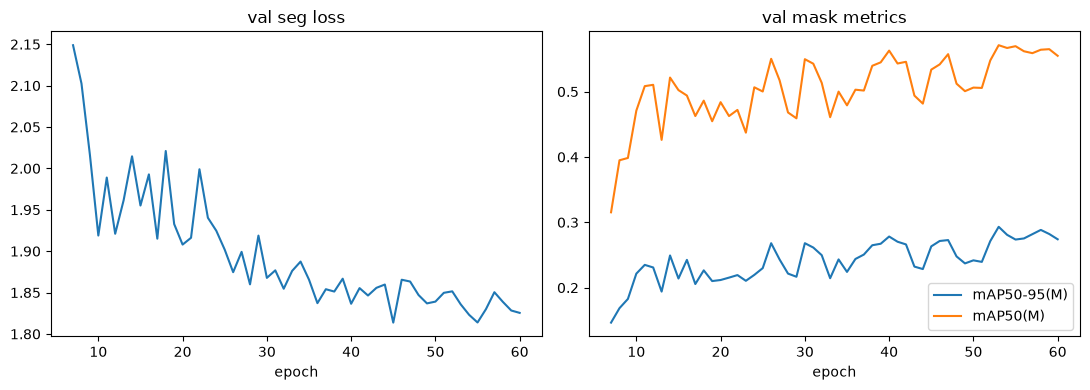

In [7]:
import pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("runs/segment/yolo_monusac_full/results.csv")
df.columns = df.columns.str.strip()          # Ultralytics pads column names with spaces
df = df[df["epoch"] > 6]                     # drop first 5 epochs

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(df["epoch"], df["val/seg_loss"]); ax[0].set(title="val seg loss", xlabel="epoch")
ax[1].plot(df["epoch"], df["metrics/mAP50-95(M)"], label="mAP50-95(M)")
ax[1].plot(df["epoch"], df["metrics/mAP50(M)"], label="mAP50(M)")
ax[1].set(title="val mask metrics", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("busi_curves_clean.png", dpi=150)

In [3]:
import os, sys
os.chdir(r"C:\Users\Razeen Basunia\group_project")   # your repo root
sys.path.insert(0, "src")
sys.path.insert(0, "scripts")
print("cwd:", os.getcwd())
import glob
print(glob.glob("runs/segment/*/weights/best.pt"))

cwd: C:\Users\Razeen Basunia\group_project
['runs/segment\\yolo_busi_e40-2\\weights\\best.pt', 'runs/segment\\yolo_busi_e40-3\\weights\\best.pt', 'runs/segment\\yolo_busi_e40-4\\weights\\best.pt', 'runs/segment\\yolo_kvasir_e40\\weights\\best.pt', 'runs/segment\\yolo_monusac\\weights\\best.pt', 'runs/segment\\yolo_monusac-2\\weights\\best.pt', 'runs/segment\\yolo_monusac-3\\weights\\best.pt', 'runs/segment\\yolo_monusac_2\\weights\\best.pt', 'runs/segment\\yolo_seg\\weights\\best.pt', 'runs/segment\\yolo_seg-4\\weights\\best.pt']


In [13]:
from eval_model import evaluate
from medseg.models.yolo.monusac_adapter import YoloSemanticAdapter

adapter = YoloSemanticAdapter(
    "runs/segment/yolo_busi_e40-4/weights/best.pt",   # from Cell 2
    conf=0.25,
    imgsz=512,
    n_classes=1,          # 4 nucleus classes + background
)

results = evaluate(
    adapter, "busi",
    splits=("test",),
    size=512,
    normalize=None,       # adapter feeds raw [0,1] images to YOLO
)
results


dataset=busi  scored_at=512  tol=2  ignore_index=None  normalize=None  device=cuda
split   images  precision     recall         f1        iou       dice        nsd
--------------------------------------------------------------------------------
test       131     0.7030     0.7513     0.7094     0.6452     0.7094     0.3757



{'test': {'precision': 0.7029592157830307,
  'recall': 0.7512680117737587,
  'f1': 0.7094490188342797,
  'iou': 0.6452234611281759,
  'dice': 0.7094490188342797,
  'nsd': 0.3756660393988952}}

In [ ]:
{'test': {'precision': 0.6718195208099367,
  'recall': 0.5505095143428245,
  'f1': 0.5716792293785834,
  'iou': 0.4633227685449503,
  'dice': 0.5716792293785834,
  'nsd': 0.49204102280220796}} -2
-3 'test': {'precision': 0.6780911080244154,
  'recall': 0.5383370878200259,
  'f1': 0.5654428222565527,
  'iou': 0.45598727924266685,
  'dice': 0.5654428222565527,
  'nsd': 0.48028888549930837}}

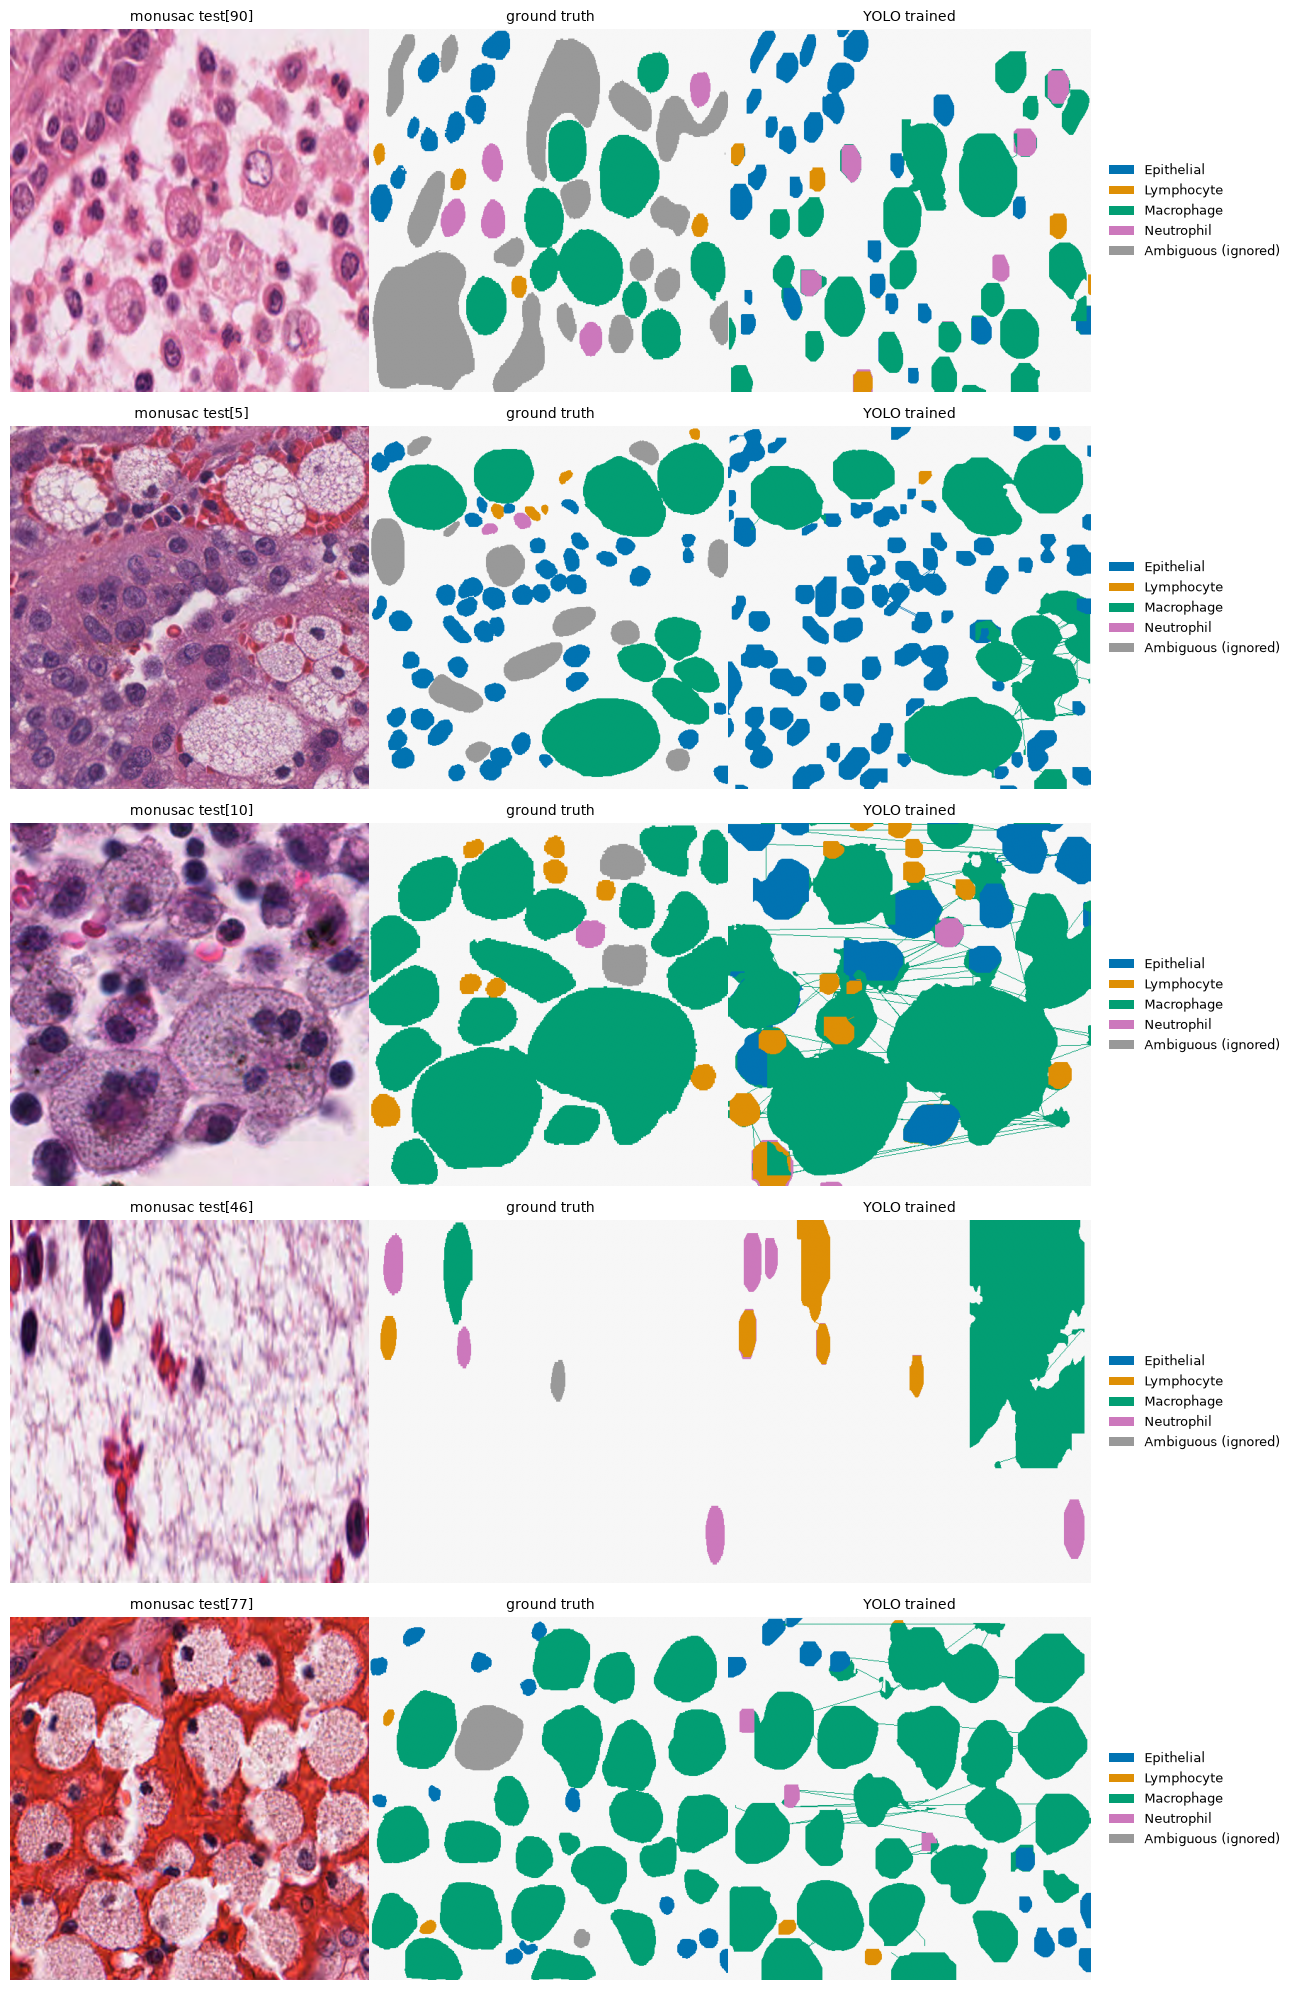

In [6]:
import sys, os
os.chdir(r"C:\Users\Razeen Basunia\group_project")
sys.path.insert(0, "src"); sys.path.insert(0, "scripts")

import numpy as np, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

from medseg.data.medseg_data import DataConfig, build_dataloaders
from medseg.models.yolo.monusac_adapter import YoloSemanticAdapter

# ---- same palette/labels as the SAM3 figure ----
MONUSAC_LABELS = ["background","Epithelial","Lymphocyte","Macrophage","Neutrophil","Ambiguous"]
AMBIGUOUS = 5
CLASS_COLORS = ["#f7f7f7","#0173B2","#DE8F05","#029E73","#CC78BC","#999999"]
MC_CMAP = ListedColormap(CLASS_COLORS)
MC_NORM = BoundaryNorm(np.arange(-0.5, 6.5, 1.0), MC_CMAP.N)

# ---- YOLO predictor: image -> (H,W) class-index map ----
adapter = YoloSemanticAdapter("runs/segment/yolo_monusac_2/weights/best.pt",
                              conf=0.1, imgsz=512, n_classes=5)

@torch.no_grad()
def yolo_labels(image):
    """(3,H,W) float image -> (H,W) predicted class indices."""
    logits = adapter(image.unsqueeze(0))          # (1,5,H,W)
    return logits.argmax(1)[0].cpu().long()

# ---- dataset ----
test_ds = build_dataloaders(DataConfig.from_yaml("configs/data/monusac.yaml"))["test"].dataset

def mc_legend(ax):
    ax.legend(handles=[Patch(facecolor=CLASS_COLORS[c],
                label=MONUSAC_LABELS[c] + (" (ignored)" if c==AMBIGUOUS else ""))
                for c in range(1,6)],
              loc="center left", bbox_to_anchor=(1.02,0.5), frameon=False, fontsize=9)

def show_yolo(indices=(90,5,10,46,77)):
    fig, axes = plt.subplots(len(indices), 3, figsize=(13, 4*len(indices)))
    for r, idx in enumerate(indices):
        s = test_ds[idx]
        img, gt = s["image"], s["mask"]
        pred = yolo_labels(img)
        panels = [(img.permute(1,2,0).numpy(), None, f"monusac test[{idx}]"),
                  (gt.numpy(), MC_CMAP, "ground truth"),
                  (pred.numpy(), MC_CMAP, "YOLO trained")]
        for col,(data,cm,title) in enumerate(panels):
            ax = axes[r,col]
            ax.imshow(data, cmap=cm, norm=MC_NORM if cm is not None else None)
            ax.set_title(title, fontsize=10); ax.axis("off")
        mc_legend(axes[r,2])
    plt.tight_layout()
    plt.savefig("yolo_monusac_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()

show_yolo()

In [5]:
import os, sys
os.chdir(r"C:\Users\Razeen Basunia\group_project")   # repo root
sys.path.insert(0, "src")
sys.path.insert(0, "scripts")   

import glob, re, csv
from eval_model import evaluate
from medseg.models.yolo.monusac_adapter import YoloSemanticAdapter

rows = []
ckpts = sorted(glob.glob("runs/segment/yolo_monusac_full/weights/epoch*.pt"),
               key=lambda p: int(re.search(r"epoch(\d+)", p).group(1)))
for ckpt in ckpts:
    ep = int(re.search(r"epoch(\d+)", ckpt).group(1))
    ad = YoloSemanticAdapter(ckpt, imgsz=512, n_classes=5)
    r = evaluate(ad, "monusac", splits=("test",), size=512, normalize=None)
    rows.append({"epoch": ep, "dice": r["test"]["dice"], "nsd": r["test"]["nsd"]})
    print(ep, round(r["test"]["dice"], 4))

with open("results/metrics/yolo_monusac_dice_per_epoch.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["epoch", "dice", "nsd"])
    w.writeheader(); w.writerows(rows)


dataset=monusac  scored_at=512  tol=2  ignore_index=5  normalize=None  device=cuda
split   images  precision     recall         f1        iou       dice        nsd
--------------------------------------------------------------------------------
test       101     0.2990     0.3471     0.2419     0.1786     0.2419     0.2256

0 0.2419

dataset=monusac  scored_at=512  tol=2  ignore_index=5  normalize=None  device=cuda
split   images  precision     recall         f1        iou       dice        nsd
--------------------------------------------------------------------------------
test       101     0.3078     0.3324     0.2425     0.1561     0.2425     0.1769

1 0.2425

dataset=monusac  scored_at=512  tol=2  ignore_index=5  normalize=None  device=cuda
split   images  precision     recall         f1        iou       dice        nsd
--------------------------------------------------------------------------------
test       101     0.2911     0.2398     0.1973     0.1320     0.1973     0.1620

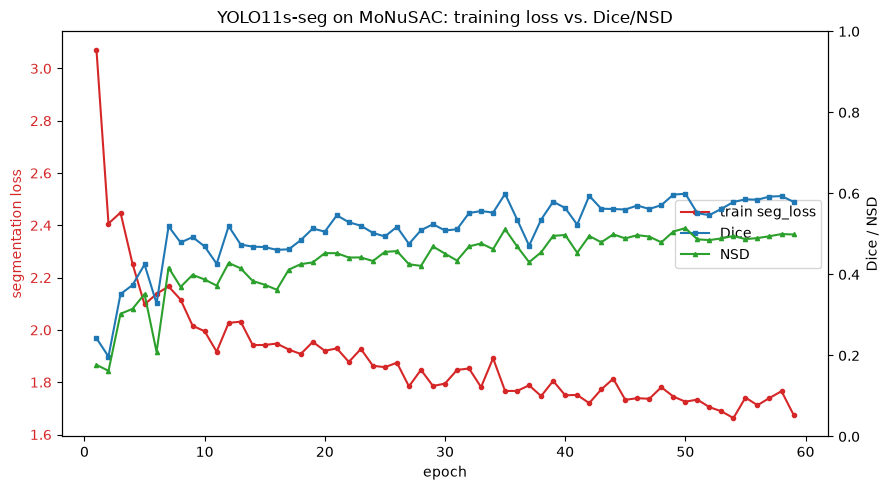

In [9]:
import pandas as pd, matplotlib.pyplot as plt

# your evaluator's per-epoch Dice/NSD
dice_df = pd.read_csv("results/metrics/yolo_monusac_dice_per_epoch.csv")

# Ultralytics' per-epoch training log (seg_loss lives here)
res_df = pd.read_csv("runs/segment/yolo_monusac_full/results.csv")
res_df.columns = res_df.columns.str.strip()   # Ultralytics pads column names with spaces

# merge on epoch
df = dice_df.merge(res_df[["epoch", "train/seg_loss"]], on="epoch", how="inner")

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(df["epoch"], df["train/seg_loss"], color="tab:red", marker="o",
         markersize=3, label="train seg_loss")
ax1.set_xlabel("epoch")
ax1.set_ylabel("segmentation loss", color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red")

ax2 = ax1.twinx()
ax2.plot(df["epoch"], df["dice"], color="tab:blue", marker="s", markersize=3, label="Dice")
ax2.plot(df["epoch"], df["nsd"], color="tab:green", marker="^", markersize=3, label="NSD")
ax2.set_ylabel("Dice / NSD", color="black")
ax2.set_ylim(0, 1)

# combined legend
l1, lab1 = ax1.get_legend_handles_labels()
l2, lab2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lab1 + lab2, loc="center right")

plt.title("YOLO11s-seg on MoNuSAC: training loss vs. Dice/NSD")
fig.tight_layout()
plt.savefig("results/figures/yolo_monusac_loss_dice_nsd.png", dpi=200, bbox_inches="tight")
plt.show()